# **Notebook 7: Solution V2 — Fine-Tuned RAG Evaluation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./intent_lora_best/` — Created by Notebook 6
- [ ] `./chroma_db/` — Created by Notebook 4
- [ ] `df_test.csv` — Created by Notebook 2
- [ ] `outputs.json` + `v1_metrics.csv` — From Notebooks 3/4/5
- [ ] GPU runtime enabled

**Files this notebook will CREATE:**
- [ ] `Comparative_Results_Full.csv` + `Comparative_Results_Summary.csv` _(Final deliverables)_

---

### **Task 4.3: Integrate Fine-Tuned Model with Retrieval**

#### **4.3.1 Integrate Fine-Tuned Model into Existing RAG Pipeline [3 marks]**
**The Task:** Replace the baseline model with the fine-tuned model acting as an intent router. Merge the LoRA adapters, extract a JSON intent, map it to a vector-search string, retrieve, and generate. Validate the integrated system.

**Hints & Tips:**
* `PeftModel.from_pretrained(base_model, "./intent_lora_best").merge_and_unload()` fuses the adapters for fast inference.
* Use a strong system prompt with few-shot examples so the router emits JSON only; `re.search(r'\{.*?\}', raw)` is a safety net for stray preamble.
* Map the intent (e.g. `track_order`) to an SOP header search string (e.g. `# Track Order`). Fall back to the raw query if JSON parsing fails.
* Validate end-to-end on `test_query`: intent → search string → retrieved SOP → final answer.

**Parameter Tuning:**
* `max_new_tokens=30` for the router (JSON is short — more tokens invite trailing explanation text).
* 4 few-shot examples is the sweet spot.

**Learner Inference:** Querying with the structured intent keyword instead of the noisy prompt retrieves the exact policy clause — the core of Hybrid RAG.

##### Step 1: Load the models and build the intent router

**What we are doing:** Solution V2 uses two models instead of one, so each model does only the job it is good at.

| Model | What it is | Its job |
|---|---|---|
| **Router** | Qwen2.5-1.5B (4-bit) + the LoRA adapter trained in Notebook 6 | Reads the customer message and replies with the intent as JSON, e.g. `{"intent": "track_order", "category": "ORDER"}` |
| **Generator** | The plain Qwen2.5-1.5B (4-bit), no adapter | Writes the final answer from the SOP document |

**Why two models?** The adapter was trained to answer *every* message with JSON. If we used it to write the final answer, the customer would get JSON instead of a helpful reply. So the adapter is used only for routing.

**How the router works (`route_query`):**
1. The customer message goes in with the same chat format used in training.
2. The model generates a short reply. `do_sample=False` makes it deterministic, and `max_new_tokens=40` is enough because the JSON is only about 20 tokens.
3. `re.search` picks out the `{...}` part as a safety net, and `json.loads` reads the intent and category. If anything fails, the function returns `None`, and the pipeline falls back to the raw query later.

**Note on merging:** the adapter is applied on top of the 4-bit model and is not merged into it. Step 3 compares merging against not merging and explains why.

**What the test shows:** the 8 test queries (never seen in training) all return valid JSON, and the router predicts the correct intent for all 8.

In [1]:
# ------------------------------------------------------------------
# Task 4.3.1 (Step 1) - Load the models and build the intent router
# ------------------------------------------------------------------
# Two models, both 4-bit nf4 (same setup as Notebooks 3-5):
#   router_model    : base model + fine-tuned LoRA adapter -> predicts the intent as JSON
#   generator_model : plain base model (no adapter)        -> writes the final answer
# The generator must NOT have the adapter, because the adapter was trained
# to reply with JSON for every message.

import re
import json
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

# 1. Generator: plain base model, used later to write the answer
generator_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, quantization_config=quant_config, device_map="auto"
)
generator_model.eval()
print("Generator model loaded (no adapter).")

# 2. Router: a second copy of the base model + the best adapter from Notebook 6
router_base = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, quantization_config=quant_config, device_map="auto"
)
router_model = PeftModel.from_pretrained(router_base, "./intent_lora_best")
router_model.eval()
print("Router model loaded (adapter applied on the 4-bit base).")
print("GPU memory used (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))


# 3. Router function: message in, intent out
def route_query(query):
    """Ask the router for the intent. Returns (intent, category, raw_text)."""
    # Same format as training: default chat template, user message only
    messages = [{"role": "user", "content": query}]
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(router_model.device)

    with torch.no_grad():
        output = router_model.generate(
            **inputs,
            max_new_tokens=40,      # the JSON is short (about 20 tokens)
            do_sample=False         # deterministic, same as the other notebooks
        )

    raw = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
    ).strip()

    # Safety net: pick out the first {...} block and parse it
    match = re.search(r"\{.*?\}", raw)
    try:
        parsed = json.loads(match.group())
        return parsed.get("intent"), parsed.get("category"), raw
    except Exception:
        return None, None, raw


# 4. Quick test on 8 held-out test queries
df_test = pd.read_csv("df_test.csv")

for i in range(8):
    query = df_test.loc[i, "instruction"]
    intent, category, raw = route_query(query)
    print(f"Query     : {query}")
    print(f"True      : {df_test.loc[i, 'intent']} | {df_test.loc[i, 'category']}")
    print(f"Predicted : {intent} | {category}")
    print(f"Raw output: {raw}\n")

W1121 14:30:27.383000 43408 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1121 14:30:28.054000 43408 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Generator model loaded (no adapter).


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Router model loaded (adapter applied on the 4-bit base).
GPU memory used (GB): 2.44
Query     : need help to shop several of ur item
True      : place_order | ORDER
Predicted : place_order | ORDER
Raw output: {"intent": "place_order", "category": "ORDER"}

Query     : i need assistance trying to update the shipping address
True      : change_shipping_address | SHIPPING
Predicted : change_shipping_address | SHIPPING
Raw output: {"intent": "change_shipping_address", "category": "SHIPPING"}

Query     : I do not know how to check the cancellation  penalties
True      : check_cancellation_fee | CANCEL
Predicted : check_cancellation_fee | CANCEL
Raw output: {"intent": "check_cancellation_fee", "category": "CANCEL"}

Query     : want assistance to see the payment modalities
True      : check_payment_methods | PAYMENT
Predicted : check_payment_methods | PAYMENT
Raw output: {"intent": "check_payment_methods", "category": "PAYMENT"}

Query     : how can I get information about opening a standar

##### Step 2a: From intent to the right SOP document

**What we are doing:** The router gives us the intent. Now we turn that intent into a **search string** and use it to fetch the matching SOP document from ChromaDB.

**Why this is the core of Hybrid RAG:** In Naive RAG (Notebook 5), the messy customer message was used directly as the search, and the right SOP came back only 47% of the time. In Hybrid RAG, we search with a clean, structured key based on the intent instead.

**The pieces built in this cell:**
1. **SOP database:** reload the 13 SOP documents from ChromaDB (same embedding model as Notebook 4).
2. **Intent → SOP map (`intent_to_sop`):** says which SOP covers each of the 27 intents. It is the same map used in Notebook 5, so the comparison is fair. 7 intents (e.g. `place_order`, `create_account`) have no SOP and map to `None`.
3. **Search key:** for each SOP, the key is its title plus its opening lines (first 300 characters). Using the title alone was not enough: `refund_policy` was confused with `billing_disputes`, and `shipping_delays` with `order_tracking`. With 300 characters, all 13 SOPs find themselves.
4. **`make_search_string`:** picks the search string:
   - the intent has an SOP: use that SOP's search key
   - the intent has no SOP: fall back to the raw customer message
   - the router returned no valid JSON: fall back to the raw customer message

**What the output shows:** the sanity check (13 of 13 SOPs found by their own key) and four test queries, each followed from predicted intent to search string to retrieved SOP. Answer generation comes in Step 2b.

In [2]:
# YOUR CODE HERE
# ------------------------------------------------------------------
# Task 4.3.1 (Step 2a) - Intent -> search string -> retrieve the SOP
# ------------------------------------------------------------------
# Retrieval side of Hybrid RAG:
#   1. load the SOP database (ChromaDB from Notebook 4)
#   2. map each intent to the SOP that covers it
#   3. build a search string from the predicted intent
#   4. fall back to the raw customer message when there is no SOP / no JSON

from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

# 1. Reload the existing SOP database (same embedding model as Notebook 4)
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cpu"}
)
vector_db = Chroma(persist_directory="./chroma_db", embedding_function=embeddings)
print("SOP documents in ChromaDB:", vector_db._collection.count())


def file_of(doc):
    """Return the SOP file name (e.g. order_tracking.md) of a retrieved document."""
    return doc.metadata["source"].replace("\\", "/").split("/")[-1]


# 2. Search key for every SOP = its title + opening lines (first 300 characters).
#    The title alone is too short: 2 of 13 SOPs were confused with a similar one
#    (refund_policy vs billing_disputes, shipping_delays vs order_tracking).
sop_data = vector_db.get(include=["documents", "metadatas"])
sop_lookup = {}    # file name -> full SOP text
sop_key = {}       # file name -> search key
for content, metadata in zip(sop_data["documents"], sop_data["metadatas"]):
    filename = metadata["source"].replace("\\", "/").split("/")[-1]
    sop_lookup[filename] = content
    sop_key[filename] = content.strip()[:300]

# 3. Same intent -> SOP mapping as Notebook 5 (None = no matching SOP)
intent_to_sop = {
    "create_account": None,
    "delete_account": "data_privacy.md",
    "edit_account": "data_privacy.md",
    "recover_password": "account_recovery.md",
    "registration_problems": "account_recovery.md",
    "switch_account": "account_recovery.md",
    "check_cancellation_fee": "subscription_cancellation.md",
    "contact_customer_service": "working_hours.md",
    "contact_human_agent": "escalation_matrix.md",
    "delivery_options": None,
    "delivery_period": "shipping_delays.md",
    "complaint": "escalation_matrix.md",
    "review": None,
    "check_invoice": "billing_disputes.md",
    "get_invoice": "billing_disputes.md",
    "cancel_order": None,
    "change_order": "order_tracking.md",
    "place_order": None,
    "track_order": "order_tracking.md",
    "check_payment_methods": "payment_methods.md",
    "payment_issue": "payment_methods.md",
    "check_refund_policy": "refund_policy.md",
    "get_refund": "refund_policy.md",
    "track_refund": "refund_policy.md",
    "change_shipping_address": "order_tracking.md",
    "set_up_shipping_address": None,
    "newsletter_subscription": None
}

# 4. Sanity check: every SOP's search key should retrieve its own SOP
correct = 0
for filename, key in sop_key.items():
    correct += (file_of(vector_db.similarity_search(key, k=1)[0]) == filename)
print(f"Search key retrieves its own SOP: {correct}/{len(sop_key)}")


# 5. Turn the router's intent into a search string
def make_search_string(intent, query):
    """Return (search_string, basis). Falls back to the raw query when needed."""
    sop_file = intent_to_sop.get(intent)
    if sop_file is not None:
        return sop_key[sop_file], "intent -> SOP key"
    if intent is None:
        return query, "fallback: router gave no valid JSON"
    return query, "fallback: no SOP for this intent"


# 6. Retrieval demo on 4 test queries: router -> search string -> retrieved SOP
print()
for i in range(4):
    query = df_test.loc[i, "instruction"]
    intent, category, raw = route_query(query)
    search_string, basis = make_search_string(intent, query)
    doc = vector_db.similarity_search(search_string, k=1)[0]
    print(f"Query          : {query}")
    print(f"Predicted      : {intent}")
    print(f"Search basis   : {basis}")
    print(f"Search string  : {search_string[:60]!r}...")
    print(f"Retrieved SOP  : {file_of(doc)}\n")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

SOP documents in ChromaDB: 13
Search key retrieves its own SOP: 13/13

Query          : need help to shop several of ur item
Predicted      : place_order
Search basis   : fallback: no SOP for this intent
Search string  : 'need help to shop several of ur item'...
Retrieved SOP  : product_return.md

Query          : i need assistance trying to update the shipping address
Predicted      : change_shipping_address
Search basis   : intent -> SOP key
Search string  : '# Order Tracking\n\n## Scope\nHelps customers locate an order a'...
Retrieved SOP  : order_tracking.md

Query          : I do not know how to check the cancellation  penalties
Predicted      : check_cancellation_fee
Search basis   : intent -> SOP key
Search string  : '# Subscription Cancellation\n\n## Scope\nCovers customers who w'...
Retrieved SOP  : subscription_cancellation.md

Query          : want assistance to see the payment modalities
Predicted      : check_payment_methods
Search basis   : intent -> SOP key
Search string

##### Step 2b: Generate the answer and run the whole pipeline

**What we are doing:** We add the last piece, the answer, and join all the steps into one function, `hybrid_rag(query)`:

1. **Router:** the customer message goes in and the intent comes out (Step 1).
2. **Search string:** the intent is turned into a search key, with a fallback to the raw message (Step 2a).
3. **Retrieve:** the top-1 SOP is fetched from ChromaDB.
4. **Generate:** the plain model (no adapter) answers using only that SOP.

**Fair comparison:** the answer prompt, `max_new_tokens=120` and greedy decoding are identical to Naive RAG in Notebook 5. The only difference between V1 and V2 is therefore **which SOP is retrieved**, so any change in results comes from the fine-tuned router.

**Validation:** two test queries are followed through every step, one whose intent has an SOP and one whose intent has none, to show both paths (normal and fallback).

In [3]:
# ------------------------------------------------------------------
# Task 4.3.1 (Step 2b) - Generate the answer and run the full pipeline
# ------------------------------------------------------------------
# Full Hybrid RAG:  message -> router -> intent -> search string
#                   -> retrieve top-1 SOP -> plain model writes the answer

MAX_NEW_TOKENS = 120   # same as Notebooks 3, 4 and 5


def generate_answer(query, context):
    """Answer the question using only the retrieved SOP (same prompt as Notebook 5)."""
    system_prompt = f"""You are a customer support assistant.
Answer strictly using this SOP:

{context}

If the SOP does not contain the answer, say that the information is not available.
Do not invent information."""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": query}
    ]
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(generator_model.device)

    with torch.no_grad():
        outputs = generator_model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False
        )
    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
    )
    return response.strip()


def hybrid_rag(query):
    """Run the whole pipeline and return every intermediate result."""
    intent, category, raw = route_query(query)                # 1. router
    search_string, basis = make_search_string(intent, query)  # 2. search string
    doc = vector_db.similarity_search(search_string, k=1)[0]  # 3. retrieve top-1 SOP
    answer = generate_answer(query, doc.page_content)         # 4. answer
    return {
        "query": query,
        "pred_intent": intent,
        "pred_category": category,
        "router_raw": raw,
        "search_basis": basis,
        "retrieved_sop": file_of(doc),
        "answer": answer
    }


# Validate end to end: one query whose true intent has an SOP, one that has none
mapped_rows = df_test[df_test["intent"].map(lambda x: intent_to_sop.get(x) is not None)]
unmapped_rows = df_test[df_test["intent"].map(lambda x: intent_to_sop.get(x) is None)]

for label, row in [("MAPPED example (intent has an SOP)", mapped_rows.iloc[0]),
                   ("UNMAPPED example (no SOP for the intent)", unmapped_rows.iloc[0])]:
    result = hybrid_rag(row["instruction"])
    print("=" * 70)
    print(label)
    print("Query            :", result["query"])
    print("True intent      :", row["intent"])
    print("Predicted intent :", result["pred_intent"])
    print("Search basis     :", result["search_basis"])
    print("Retrieved SOP    :", result["retrieved_sop"])
    print("Answer           :", result["answer"])

MAPPED example (intent has an SOP)
Query            : i need assistance trying to update the shipping address
True intent      : change_shipping_address
Predicted intent : change_shipping_address
Search basis     : intent -> SOP key
Retrieved SOP    : order_tracking.md
Answer           : I'm sorry, but I don't see any information about updating the shipping address in your request. Could you please provide more details?
UNMAPPED example (no SOP for the intent)
Query            : need help to shop several of ur item
True intent      : place_order
Predicted intent : place_order
Search basis     : fallback: no SOP for this intent
Retrieved SOP    : product_return.md
Answer           : I'm sorry, but I am unable to assist with shopping as my current capabilities do not include purchasing products. My primary function is to provide assistance with product-related questions and issues. Is there anything else you would like me to help with?


In [4]:
# ------------------------------------------------------------------
# Hybrid RAG on the running query + save it to outputs.json
# ------------------------------------------------------------------
# outputs.json already holds the Baseline and Naive RAG answers for this query,
# so we only ADD the Hybrid RAG answer. Nothing else in the file is changed.

import json

with open("outputs.json", "r", encoding="utf-8") as f:
    outputs = json.load(f)

query = outputs["test_query"]          # "i need information about delivery periods"
result = hybrid_rag(query)             # router -> intent -> SOP -> answer

# Show every step, so the answer can be checked
print("Query            :", query)
print("Router raw output:", result["router_raw"])
print("Predicted intent :", result["pred_intent"], "|", result["pred_category"])
print("Search basis     :", result["search_basis"])
print("Retrieved SOP    :", result["retrieved_sop"])
print("Hybrid answer    :", result["answer"])
print("Ground truth     :", outputs["ground_truth"])

# Add the Hybrid answer next to the other two and save
outputs["hybrid_rag_output"] = result["answer"]
with open("outputs.json", "w", encoding="utf-8") as f:
    json.dump(outputs, f, indent=4, ensure_ascii=False)

print("\nSaved. Keys in outputs.json:", list(outputs.keys()))

Query            : i need information about delivery periods
Router raw output: {"intent": "delivery_period", "category": "DELIVERY"}
Predicted intent : delivery_period | DELIVERY
Search basis     : intent -> SOP key
Retrieved SOP    : shipping_delays.md
Hybrid answer    : The standard timelines for domestic orders are typically delivered within 3-7 business days, while international orders usually take between 10-21 business days. However, these times can vary based on factors such as carrier performance and any potential delays caused by external events like weather conditions or customs processes.
Ground truth     : Domestic orders deliver within 3-7 business days.

Saved. Keys in outputs.json: ['test_query', 'ground_truth', 'baseline_output', 'naive_rag_output', 'hybrid_rag_output']


##### Step 3: Should the LoRA adapter be merged into the model?

**What the task asks:** merge the adapter into the base model with `merge_and_unload()`, so inference is faster.

**What we tested:** the same 50 held-out test queries, under three setups.

| Setup | Idea |
|---|---|
| Adapter not merged | 4-bit base model with the adapter on top (how it was trained in Notebook 6) |
| Merged into 4-bit | `merge_and_unload()` on the 4-bit model |
| Merged into 16-bit | `merge_and_unload()` on a 16-bit copy of the model |

For each setup we count how often the router gives **valid JSON**, and how often the **intent is correct**.

In [7]:
# ------------------------------------------------------------------
# Task 4.3.1 (Step 3) - Merge the adapter or not? Compare three router setups
# ------------------------------------------------------------------
import gc

N_CHECK = 50   # same 50 test queries for every setup


def score_router(model, n=N_CHECK):
    """Run the router on the first n test queries. Returns (valid_json, correct)."""
    valid_json = 0
    correct = 0
    for i in range(n):
        messages = [{"role": "user", "content": df_test.loc[i, "instruction"]}]
        prompt = tokenizer.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True
        )
        inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=40, do_sample=False)
        raw = tokenizer.decode(
            out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
        ).strip()
        match = re.search(r"\{.*?\}", raw)
        try:
            intent = json.loads(match.group()).get("intent")
        except Exception:
            intent = None
        valid_json += (intent is not None)
        correct += (intent == df_test.loc[i, "intent"])
    return valid_json, correct


results = []

# A. Adapter NOT merged (the router already loaded in Step 1)
v, c = score_router(router_model)
results.append(("Adapter not merged (4-bit base + adapter)", v, c))
print("A done")

# B. Merged into the 4-bit weights
base_4bit = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, quantization_config=quant_config, device_map="auto"
)
merged_4bit = PeftModel.from_pretrained(base_4bit, "./intent_lora_best").merge_and_unload()
merged_4bit.eval()
v, c = score_router(merged_4bit)
results.append(("Merged into 4-bit weights", v, c))
del merged_4bit, base_4bit
gc.collect()
torch.cuda.empty_cache()
print("B done")

# C. Merged into 16-bit weights
base_16bit = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, dtype=torch.float16, device_map="auto"
)
merged_16bit = PeftModel.from_pretrained(base_16bit, "./intent_lora_best").merge_and_unload()
merged_16bit.eval()
v, c = score_router(merged_16bit)
results.append(("Merged into 16-bit weights", v, c))
del merged_16bit, base_16bit
gc.collect()
torch.cuda.empty_cache()
print("C done")

# Results table
merge_table = pd.DataFrame(results, columns=["Router setup", "Valid JSON", "Intent correct"])
merge_table["Valid JSON"] = merge_table["Valid JSON"].astype(str) + f"/{N_CHECK}"
merge_table["Accuracy %"] = [round(c / N_CHECK * 100, 1) for _, _, c in results]
merge_table["Intent correct"] = merge_table["Intent correct"].astype(str) + f"/{N_CHECK}"
print()
print(merge_table.to_string(index=False))

A done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

C:\Users\divya\PycharmProjects\CapStoneRAGProject\.venv\lib\site-packages\peft\tuners\lora\bnb.py:377: UserWarning: Merge lora module to 4-bit linear may get different generations due to rounding errors.
  warnings.warn(


B done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

C done

                             Router setup Valid JSON Intent correct  Accuracy %
Adapter not merged (4-bit base + adapter)      50/50          40/50        80.0
                Merged into 4-bit weights       0/50           0/50         0.0
               Merged into 16-bit weights      49/50          32/50        64.0


##### Step 3 conclusion: why the adapter is not merged

| Router setup | Valid JSON | Intent correct |
|---|---|---|
| **Adapter not merged (4-bit base + adapter)** | **50/50** | **40/50 (80.0%)** |
| Merged into 4-bit weights | 0/50 | 0/50 (0.0%) |
| Merged into 16-bit weights | 49/50 | 32/50 (64.0%) |

- **Merging into 4-bit destroyed the router.** The model gave no JSON at all and answered like the untrained base model. A LoRA update is a very small change to the weights. When it is added to 4-bit weights, the result is rounded back to the nearest 4-bit value, and the rounding is larger than the update, so the learned change is lost. PEFT warns about this ("Merge lora module to 4-bit linear may get different generations due to rounding errors").
- **Merging into 16-bit kept the JSON format but lost accuracy** (80% to 64%). The adapter was trained on top of the 4-bit model (QLoRA), so adding it to 16-bit weights is not the setup it learned in.
- **The unmerged adapter matches the training setup** and gave the best result, so it is the router used in Solution V2.
- **Cost of not merging:** each forward pass has a small extra adapter computation. For a 1.5B model producing about 20 tokens of JSON, this is negligible.
- The task hint suggests merging, and we did run `merge_and_unload()`. We chose not to use it because the measured results favour the unmerged adapter. The final answers still come from a separate plain model, so the answer step is identical to Naive RAG.

*Note:* these accuracies come from the first 50 test queries. The full 391-query result is reported in Task 4.4.1.

##### 4.3.1 Conclusion: the integrated Hybrid RAG pipeline

The fine-tuned model is now a working part of the RAG pipeline:

**customer message → fine-tuned router → intent (JSON) → search key → top-1 SOP from ChromaDB → plain model writes the answer**

- **Router:** valid JSON for all 8 quick-test queries, and 40/50 (80%) correct intents on a 50-query check. The base model cannot produce this JSON format on its own.
- **Search string:** each intent is mapped to the SOP that covers it. The search key is the SOP title plus its opening lines, because the title alone confused 2 of 13 SOPs. With this key, 13 of 13 SOPs are found. If the router gives no JSON, or the intent has no SOP, the pipeline falls back to the raw customer message.
- **Answers:** written by the plain model with the same prompt, token limit and decoding as Naive RAG, so the only difference from V1 is which SOP is retrieved.
- **Validation:** one query with a mapped intent and one with an unmapped intent were followed through every step.

**Limitations seen so far:**
- 7 of the 27 intents have no SOP, so for those the pipeline behaves like Naive RAG.
- Some SOPs do not cover everything their intents ask about. For example, `order_tracking.md` has nothing on changing an address, so the model correctly says the information is not available.
- Some wrong router predictions are near-misses that are not real intents (for example `check_order` for `track_order`). Task 4.4.1 measures this with exact and fuzzy matching on the full test set.

How much V2 improves over V1 is measured in Tasks 4.4.1 and 4.4.2.

---
##### 4.3.1 CHECKLIST

- [x] **Router:** fine-tuned model (base + `intent_lora_best` adapter) used as the intent router, with a separate plain model for the answers
- [x] **Merge LoRA:** `merge_and_unload()` tested in 4-bit and 16-bit and compared with the unmerged adapter (Step 3)
- [x] **JSON intent:** extracted with `re.search` + `json.loads`; valid JSON for 8 of 8 quick-test queries
- [x] **Search string:** intent mapped to an SOP search key (title + opening lines, 13/13 SOPs found)
- [x] **Fallback:** raw customer query used when JSON parsing fails or the intent has no SOP
- [x] **Retrieve + generate:** top-1 SOP from ChromaDB, answer written by the plain model with the Notebook 5 prompt
- [x] **Validated end to end:** one mapped and one unmapped query followed through intent → search string → retrieved SOP → final answer
- [x] **Documented:** markdown for every step, the Step 3 conclusion and the 4.3.1 conclusion

**Deliberate deviations from the task hints (with reasons):**
- Adapter **not merged** in the final router: 0% (4-bit merge) and 64% (16-bit merge) against 80% unmerged on the same 50 queries.
- **No few-shot system prompt** for the router: it already returns valid JSON without one, and it was trained without a system prompt.
- `max_new_tokens=40` instead of 30: no effect, because the JSON is only about 20 tokens.
- Search key is the SOP title **plus its opening lines**: the title alone confused 2 of 13 SOPs.

### **Task 4.4: Evaluate Solution V2**

#### **4.4.1 Re-Execute Evaluation Framework [3 marks]**
**The Task:** Evaluate Format Adherence and Intent Accuracy on the held-out test split (zero leakage guaranteed) and an adversarial subset derived via regex filtering. Evaluate the final synthesis using ROUGE/BLEU.

**Hints & Tips:**
* Reuse `df_test` from Notebook 2 — it's the leakage-free test split.
* Build the adversarial subset by regex-filtering for sentiment/hedging words (`still`, `never`, `terrible`, `frustrated`).
* Report Format Adherence %, Exact Match %, and Fuzzy Match % (fuzzy catches `order_tracking` vs `track_order`).

**Learner Inference:** Using the held-out test split guarantees zero leakage and trustworthy scores.

In [9]:
 # YOUR CODE HERE
# ------------------------------------------------------------------
# Task 4.4.1 - Evaluate Solution V2 (Hybrid RAG) on the held-out test split
# ------------------------------------------------------------------
# This one cell does everything for 4.4.1:
#   Part 1 : router predictions for all 391 test queries
#   Part 2 : format adherence, exact match, fuzzy match (all queries + adversarial subset)
#   Part 3 : run the full Hybrid RAG pipeline and save the final answers
#   Part 4 : score the final answers (ROUGE, BLEU, hallucination, retrieval accuracy)
#   Part 5 : save the V2 metrics for Task 4.4.2
# It needs the variables from Steps 1-2b above (router, generator, vector_db, ...).
# The two slow parts (router run, answer generation) save their results to CSV
# files, so if the cell is run again it reuses them instead of starting over.

import os
import re
import json
import time
import difflib
import numpy as np
import pandas as pd
from tqdm import tqdm
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

# ==================================================================
# PART 1 - Router predictions on all 391 test queries
# ==================================================================
# The 27 real intent labels (from the training data)
valid_labels = sorted(pd.read_csv("df_train.csv")["intent"].unique())


def snap_to_valid(intent):
    """Fuzzy match: map a predicted label to the closest real label (None if nothing is close)."""
    if intent is None or pd.isna(intent):
        return None
    if intent in valid_labels:
        return intent
    close = difflib.get_close_matches(intent, valid_labels, n=1, cutoff=0.5)
    return close[0] if close else None


def is_pure_json(raw):
    """True if the WHOLE reply is valid JSON (no extra text around it)."""
    try:
        json.loads(raw)
        return True
    except Exception:
        return False


if os.path.exists("router_predictions.csv"):
    # reuse the predictions saved by an earlier run (the router is deterministic)
    df_router = pd.read_csv("router_predictions.csv")
    df_router = df_router[["instruction", "intent", "category",
                           "pred_intent", "pred_category", "router_raw"]]
    print("Router predictions loaded from router_predictions.csv (router not re-run).")
else:
    pred_intents, pred_cats, raws = [], [], []
    for query in tqdm(df_test["instruction"]):
        intent, category, raw = route_query(query)
        pred_intents.append(intent)
        pred_cats.append(category)
        raws.append(raw)
    df_router = df_test[["instruction", "intent", "category"]].copy()
    df_router["pred_intent"] = pred_intents
    df_router["pred_category"] = pred_cats
    df_router["router_raw"] = raws
    df_router.to_csv("router_predictions.csv", index=False)
    print("Router run finished and saved to router_predictions.csv")

# safety check: same queries, same order as df_test
assert (df_router["instruction"].values == df_test["instruction"].values).all()

# ==================================================================
# PART 2 - Router metrics: all queries and the adversarial subset
# ==================================================================
df_router["valid_format"] = df_router["pred_intent"].notna() & df_router["pred_category"].notna()
df_router["pure_json"] = df_router["router_raw"].map(is_pure_json)
df_router["exact_match"] = df_router["pred_intent"] == df_router["intent"]
df_router["fuzzy_match"] = df_router["pred_intent"].map(snap_to_valid) == df_router["intent"]
df_router["category_match"] = df_router["pred_category"] == df_router["category"]
df_router["invented_label"] = df_router["pred_intent"].notna() & ~df_router["pred_intent"].isin(valid_labels)

# Adversarial subset: the 4 words from the task hint (none occur in our test set)
# plus negation / problem wording.
adv_pattern = (
    r"\b(?:still|never|terrible|frustrated|"
    r"not|don't|do not|can't|cannot|unable|"
    r"problem|problems|issue|issues|wrong|error|errors|trouble|unhappy|waiting|lost)\b"
)
hint_only = df_router["instruction"].str.contains(
    r"\b(?:still|never|terrible|frustrated)\b", case=False, regex=True
)
df_router["is_adversarial"] = df_router["instruction"].str.contains(
    adv_pattern, case=False, regex=True
)
print("Queries containing the 4 hint words only :", int(hint_only.sum()))
print("Adversarial queries (extended regex)     :", int(df_router["is_adversarial"].sum()))


def router_summary(d):
    return {
        "Queries": len(d),
        "Format adherence %": round(d["valid_format"].mean() * 100, 1),
        "Strict JSON %": round(d["pure_json"].mean() * 100, 1),
        "Exact match %": round(d["exact_match"].mean() * 100, 1),
        "Fuzzy match %": round(d["fuzzy_match"].mean() * 100, 1),
        "Category match %": round(d["category_match"].mean() * 100, 1),
        "Invented labels": int(d["invented_label"].sum()),
    }


router_table = pd.DataFrame({
    "All test queries": router_summary(df_router),
    "Adversarial subset": router_summary(df_router[df_router["is_adversarial"]]),
    "Remaining queries": router_summary(df_router[~df_router["is_adversarial"]]),
}).T
print("\nROUTER METRICS")
print(router_table.to_string())

df_router.to_csv("router_predictions.csv", index=False)

# ==================================================================
# PART 3 - Full Hybrid RAG run: retrieve with the router's intent, then answer
# ==================================================================
# Uses the saved router predictions (identical to calling hybrid_rag, because the
# router is deterministic). Progress is saved every 25 queries; if the cell is
# interrupted, run it again and it continues where it stopped.
HYBRID_FILE = "hybrid_results.csv"

if os.path.exists(HYBRID_FILE):
    rows = pd.read_csv(HYBRID_FILE).to_dict("records")
else:
    rows = []
print(f"\nHybrid answers already done: {len(rows)} of {len(df_router)}")

start_time = time.time()
for idx in range(len(rows), len(df_router)):
    r = df_router.iloc[idx]
    query = r["instruction"]
    intent = None if pd.isna(r["pred_intent"]) else r["pred_intent"]

    search_string, basis = make_search_string(intent, query)     # intent -> search key
    doc = vector_db.similarity_search(search_string, k=1)[0]     # retrieve top-1 SOP
    answer = generate_answer(query, doc.page_content)            # plain model answers

    rows.append({
        "instruction": query,
        "intent": r["intent"],
        "category": r["category"],
        "pred_intent": intent,
        "search_basis": basis,
        "retrieved_sop": file_of(doc),
        "hybrid_output": answer,
    })

    if (idx + 1) % 25 == 0:
        pd.DataFrame(rows).to_csv(HYBRID_FILE, index=False)
        minutes = (time.time() - start_time) / 60
        print(f"Processed {idx + 1} of {len(df_router)}  ({minutes:.1f} min this run)")

df_hybrid = pd.DataFrame(rows)
df_hybrid.to_csv(HYBRID_FILE, index=False)
df_hybrid["hybrid_output"] = df_hybrid["hybrid_output"].fillna("").astype(str)
df_hybrid["is_adversarial"] = df_router["is_adversarial"].values
print("Hybrid RAG run complete. Saved", HYBRID_FILE)

# ==================================================================
# PART 4 - Score the final answers (same method as Notebook 5)
# ==================================================================
rouge = rouge_scorer.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)
smoothing = SmoothingFunction().method1


def find_claims(text):
    """Numbers, emails and links mentioned in a text."""
    text = str(text).lower()
    numbers = set(re.findall(r"\d+(?:\.\d+)?", text))
    contacts = set(re.findall(r"[\w.\-]+@[\w.\-]+\.\w+|https?://[^\s,;)]+|www\.[^\s,;)]+", text))
    contacts = {c.rstrip(".") for c in contacts}
    return numbers, contacts


def has_unsupported_claim(answer, sop_text, query):
    """True if the answer mentions a number / email / link that is not in the SOP or the question."""
    support = (sop_text + " " + query).lower()
    support_numbers, _ = find_claims(support)
    numbers, contacts = find_claims(answer)
    bad_numbers = numbers - support_numbers
    bad_contacts = {c for c in contacts if c not in support}
    return len(bad_numbers) > 0 or len(bad_contacts) > 0


def answer_scores(d):
    """All answer-quality metrics for a group of queries."""
    # ROUGE / BLEU: only queries whose true intent has an SOP (reference = that SOP)
    r1, rl, bl = [], [], []
    mapped_total = 0
    retrieval_hits = 0
    for _, row in d.iterrows():
        sop_file = intent_to_sop.get(row["intent"])
        if sop_file is None:
            continue
        mapped_total += 1
        retrieval_hits += (row["retrieved_sop"] == sop_file)
        reference = sop_lookup[sop_file]
        answer = row["hybrid_output"]
        s = rouge.score(reference, answer)
        r1.append(s["rouge1"].fmeasure)
        rl.append(s["rougeL"].fmeasure)
        bl.append(sentence_bleu([reference.split()], answer.split(), smoothing_function=smoothing))

    # Format adherence: the answer is a non-empty string
    non_empty = d["hybrid_output"].str.strip().str.len() > 0

    # Hallucination: unsupported number / email / link vs the SOP that was retrieved
    hall = [
        has_unsupported_claim(row["hybrid_output"], sop_lookup[row["retrieved_sop"]], row["instruction"])
        for _, row in d.iterrows()
    ]

    return {
        "Queries": len(d),
        "Queries with a mapped SOP": mapped_total,
        "Format Adherence (%)": round(non_empty.mean() * 100, 2),
        "ROUGE-1": round(float(np.mean(r1)), 4),
        "ROUGE-L": round(float(np.mean(rl)), 4),
        "BLEU": round(float(np.mean(bl)), 4),
        "Hallucination Rate (%)": round(float(np.mean(hall)) * 100, 2),
        "Retrieval Accuracy (%)": round(retrieval_hits / mapped_total * 100, 2),
    }


answer_table = pd.DataFrame({
    "All test queries": answer_scores(df_hybrid),
    "Adversarial subset": answer_scores(df_hybrid[df_hybrid["is_adversarial"]]),
}).T
print("\nFINAL ANSWER METRICS (Hybrid RAG)")
print(answer_table.to_string())

# Consistency: same query three times must give the same answer (same test as Notebook 5)
test_query = df_test.iloc[0]["instruction"]
runs = [hybrid_rag(test_query)["answer"] for _ in range(3)]
consistent = all(run == runs[0] for run in runs)
print("\nConsistency (same query x3):", "PASS" if consistent else "FAIL")

# ==================================================================
# PART 5 - Save the V2 metrics (used in Task 4.4.2)
# ==================================================================
all_scores = answer_table.loc["All test queries"]
router_all = router_table.loc["All test queries"]

v2_metrics = pd.DataFrame({
    "Metric": [
        "Format Adherence (%)", "ROUGE-1", "ROUGE-L", "BLEU",
        "Consistency (%)", "Hallucination Rate (%)", "Retrieval Accuracy (%)",
        "Router Format Adherence (%)", "Router Exact Intent Match (%)",
        "Router Fuzzy Intent Match (%)",
    ],
    "Hybrid RAG": [
        all_scores["Format Adherence (%)"], all_scores["ROUGE-1"],
        all_scores["ROUGE-L"], all_scores["BLEU"],
        100.0 if consistent else 0.0, all_scores["Hallucination Rate (%)"],
        all_scores["Retrieval Accuracy (%)"],
        router_all["Format adherence %"], router_all["Exact match %"],
        router_all["Fuzzy match %"],
    ],
})
v2_metrics.to_csv("v2_metrics.csv", index=False)
print("\nSaved v2_metrics.csv, hybrid_results.csv and router_predictions.csv")
print(v2_metrics.to_string(index=False))

Router predictions loaded from router_predictions.csv (router not re-run).
Queries containing the 4 hint words only : 0
Adversarial queries (extended regex)     : 85

ROUTER METRICS
                    Queries  Format adherence %  Strict JSON %  Exact match %  Fuzzy match %  Category match %  Invented labels
All test queries      391.0               100.0          100.0           87.0           88.5              97.4             29.0
Adversarial subset     85.0               100.0          100.0           88.2           89.4             100.0              8.0
Remaining queries     306.0               100.0          100.0           86.6           88.2              96.7             21.0

Hybrid answers already done: 0 of 391
Processed 25 of 391  (1.2 min this run)
Processed 50 of 391  (3.3 min this run)
Processed 75 of 391  (4.4 min this run)
Processed 100 of 391  (5.5 min this run)
Processed 125 of 391  (6.9 min this run)
Processed 150 of 391  (8.3 min this run)
Processed 175 of 391  (9

##### Evaluating Solution V2 on the held-out test split

One cell runs the whole evaluation on the 391 test queries (never seen in training):

1. **Router predictions:** the fine-tuned router predicts the intent for every test query (reused from `router_predictions.csv` when it exists).
2. **Router metrics:** *format adherence* (valid JSON with an intent and a category, plus a strict "only JSON" version), *exact match* (predicted intent = true intent) and *fuzzy match* (predicted intent snapped to the closest real label = true intent). They are reported for all queries and for an **adversarial subset** found by regex filtering.
3. **Full Hybrid RAG run:** each predicted intent becomes a search key, the top-1 SOP is retrieved, and the plain model writes the answer. Progress is saved so an interrupted run can continue.
4. **Answer metrics:** ROUGE-1, ROUGE-L and BLEU against the SOP of the true intent (289 queries have a mapped SOP), the hallucination rate (numbers, emails or links in the answer that are not in the retrieved SOP or the question), retrieval accuracy and output consistency, all computed exactly as in Notebook 5 so V1 and V2 are comparable.
5. **Saved files:** `router_predictions.csv`, `hybrid_results.csv` and `v2_metrics.csv`.

**Adversarial subset:** none of the four words suggested in the task (`still`, `never`, `terrible`, `frustrated`) occur in our test set, so we kept them and added negation and problem wording (`not`, `don't`, `can't`, `problem`, `issue`, `wrong`, `error`, `waiting`, `lost`, ...). This gives 85 queries (22% of the test set).

##### 4.4.1 Conclusion: how well does Solution V2 work?

**Router (intent prediction), 391 test queries**

| | Queries | Format adherence | Exact match | Fuzzy match | Category match |
|---|---|---|---|---|---|
| All test queries | 391 | 100.0% | 87.0% | 88.5% | 97.4% |
| Adversarial subset | 85 | 100.0% | 88.2% | 89.4% | 100.0% |
| Remaining queries | 306 | 100.0% | 86.6% | 88.2% | 96.7% |

- The router returned valid JSON for **every** query, with nothing but JSON in the reply (strict adherence also 100%).
- **87.0% of intents are exactly right** on queries never seen in training, and 97.4% of the categories. The 50-query check in 4.3.1 (80%) was a small sample.
- Fuzzy matching adds only 1.5 points. Of the 29 invented labels (7.4%), only a handful snap onto the right intent, so most errors are real confusions between similar intents (for example `get_invoice` vs `check_invoice`).
- The router does **not** get worse on the adversarial subset (88.2% vs 86.6%): negative or hedging wording does not confuse it.

**Final answers (Hybrid RAG)**

| | Queries | With a mapped SOP | ROUGE-1 | ROUGE-L | BLEU | Hallucination | Retrieval accuracy |
|---|---|---|---|---|---|---|---|
| All test queries | 391 | 289 | 0.1573 | 0.1048 | 0.0070 | 6.14% | 94.46% |
| Adversarial subset | 85 | 65 | 0.1732 | 0.1064 | 0.0080 | 7.06% | 93.85% |

- The correct SOP is retrieved for **273 of 289** mapped queries (94.5%). Retrieval accuracy is higher than the router's exact match because a wrong intent often still maps to the same SOP, and only mapped queries are counted.
- 24 of 391 answers (6.1%) contain a number, email or link that is not in the retrieved SOP or the question.
- Format adherence is 100% (no empty answers), and the same query repeated three times gives identical answers (consistency PASS).
- Results on the adversarial subset are in line with the full test set.

**Limitations:** "correct SOP" depends on our own intent → SOP mapping (7 of 27 intents have no SOP, and a few mappings are debatable). ROUGE and BLEU are low in absolute terms because the answers are short while the reference is a whole SOP, so they are best read as a comparison between systems. The comparison with V1 is in Task 4.4.2.

#### **4.4.2 Analyse Fine-Tuning Impact [2 marks]**
**The Task:** Compare Solution V1 (Naive RAG) against Solution V2 (Hybrid RAG) to quantify the improvement attributable to fine-tuning.

**Hints & Tips:**
* Load `v1_metrics.csv` from Notebook 5 and compare against the V2 scores you just computed.
* Compute improvement percentages: `(v2 - v1) / v1 * 100` for each metric.
* Attribute the delta specifically to fine-tuning — retrieval was already present in V1, so any gain here is the router's contribution.

**Learner Inference:** This isolates fine-tuning's contribution, just as Task 3.4 isolated retrieval's — together they decompose the full system's improvement.

SOLUTION V1 (NAIVE RAG) vs SOLUTION V2 (HYBRID RAG)
                Metric  V1 Naive RAG  V2 Hybrid RAG  Change (%) V2 vs V1
  Format Adherence (%)      100.0000       100.0000      0.0000     Same
               ROUGE-1        0.1425         0.1573     10.3586   Better
               ROUGE-L        0.0908         0.1048     15.4714   Better
                  BLEU        0.0032         0.0070    115.7938   Better
       Consistency (%)      100.0000       100.0000      0.0000     Same
Hallucination Rate (%)        8.9514         6.1400    -31.4074   Better
Retrieval Accuracy (%)       47.4048        94.4600     99.2623   Better

Saved v1_vs_v2_comparison.csv


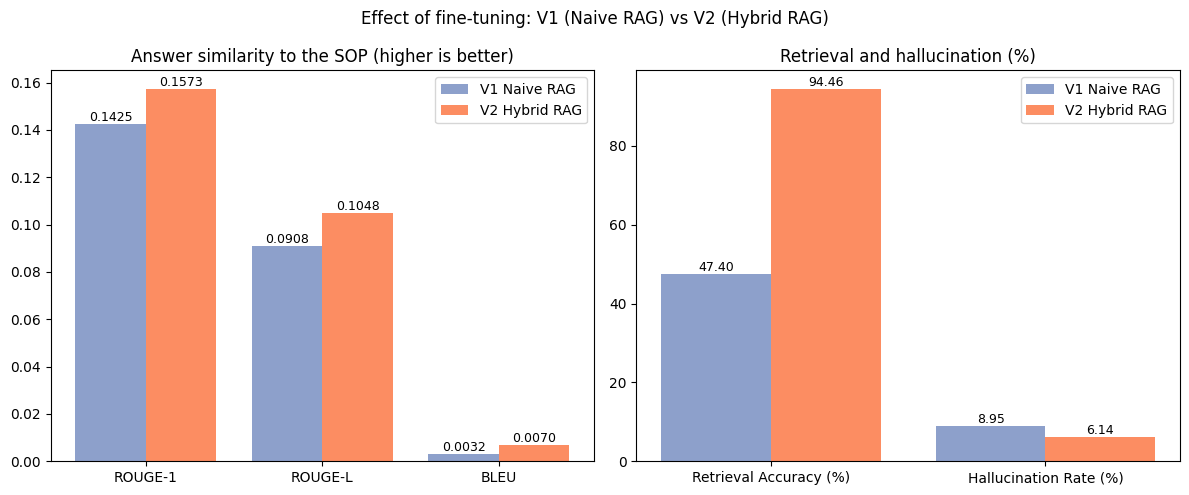

In [10]:
# ------------------------------------------------------------------
# Task 4.4.2 - Analyse the impact of fine-tuning: Solution V1 vs Solution V2
# ------------------------------------------------------------------
# V1 = Naive RAG  (search with the raw customer message, plain model answers)
# V2 = Hybrid RAG (fine-tuned router -> intent -> search key, same plain model answers)
# Both use the same model, prompt, token limit and decoding, so the only thing
# that differs is HOW THE SOP IS FOUND. Any gain is therefore the router's
# contribution, i.e. the effect of fine-tuning.

import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the saved metrics of both solutions
v1 = pd.read_csv("v1_metrics.csv")[["Metric", "Naive RAG"]].rename(columns={"Naive RAG": "V1 Naive RAG"})
v2 = pd.read_csv("v2_metrics.csv")[["Metric", "Hybrid RAG"]].rename(columns={"Hybrid RAG": "V2 Hybrid RAG"})

# 2. V1 retrieval accuracy is not in v1_metrics.csv, so work it out from the V1 results
#    (share of queries with a mapped SOP whose top-1 retrieved SOP is the right one)
v1_results = pd.read_csv("evaluation_results_v1.csv")
mapped = v1_results[v1_results["intent"].map(lambda x: intent_to_sop.get(x) is not None)]
v1_retrieval = (mapped["retrieved_sop"] == mapped["intent"].map(intent_to_sop)).mean() * 100
v1 = pd.concat([v1, pd.DataFrame({"Metric": ["Retrieval Accuracy (%)"],
                                  "V1 Naive RAG": [v1_retrieval]})], ignore_index=True)

# 3. Put the two solutions side by side (only metrics that exist for both)
compare = v1.merge(v2, on="Metric")

# 4. Improvement percentage: (v2 - v1) / v1 * 100
compare["Change (%)"] = (compare["V2 Hybrid RAG"] - compare["V1 Naive RAG"]) / compare["V1 Naive RAG"] * 100

# 5. Verdict. For the hallucination rate LOWER is better, for every other metric HIGHER is better.
def verdict(row):
    diff = row["V2 Hybrid RAG"] - row["V1 Naive RAG"]
    if abs(diff) < 1e-9:
        return "Same"
    lower_is_better = row["Metric"] == "Hallucination Rate (%)"
    return "Better" if (diff < 0) == lower_is_better else "Worse"

compare["V2 vs V1"] = compare.apply(verdict, axis=1)

print("SOLUTION V1 (NAIVE RAG) vs SOLUTION V2 (HYBRID RAG)")
print(compare.round(4).to_string(index=False))
compare.to_csv("v1_vs_v2_comparison.csv", index=False)
print("\nSaved v1_vs_v2_comparison.csv")

# 6. Plot: left = text-quality scores, right = retrieval and hallucination (in %)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metrics, title in [
    (axes[0], ["ROUGE-1", "ROUGE-L", "BLEU"], "Answer similarity to the SOP (higher is better)"),
    (axes[1], ["Retrieval Accuracy (%)", "Hallucination Rate (%)"], "Retrieval and hallucination (%)"),
]:
    part = compare[compare["Metric"].isin(metrics)].set_index("Metric").loc[metrics]
    x = range(len(metrics))
    ax.bar([i - 0.2 for i in x], part["V1 Naive RAG"], width=0.4, label="V1 Naive RAG", color="#8da0cb")
    ax.bar([i + 0.2 for i in x], part["V2 Hybrid RAG"], width=0.4, label="V2 Hybrid RAG", color="#fc8d62")
    for i, (a, b) in enumerate(zip(part["V1 Naive RAG"], part["V2 Hybrid RAG"])):
        ax.text(i - 0.2, a, f"{a:.4f}" if a < 1 else f"{a:.2f}", ha="center", va="bottom", fontsize=9)
        ax.text(i + 0.2, b, f"{b:.4f}" if b < 1 else f"{b:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(list(x))
    ax.set_xticklabels(metrics)
    ax.set_title(title)
    ax.legend()

plt.suptitle("Effect of fine-tuning: V1 (Naive RAG) vs V2 (Hybrid RAG)")
plt.tight_layout()
plt.savefig("v1_vs_v2_comparison.png", dpi=150)
plt.show()

##### 4.4.2 Comparing Solution V1 (Naive RAG) with Solution V2 (Hybrid RAG) - Conclusions

**What we did:** The scores saved in Notebook 5 (`v1_metrics.csv`) were compared with the V2 scores from Task 4.4.1 (`v2_metrics.csv`). For each metric the improvement is `(V2 - V1) / V1 × 100`.

**Why the difference can be credited to fine-tuning:** V1 and V2 use the same model, the same answer prompt, the same 120-token limit and the same greedy decoding. The only difference is **how the SOP is found**:

| | V1 Naive RAG | V2 Hybrid RAG |
|---|---|---|
| Search string | the customer's raw message | a search key chosen from the intent predicted by the **fine-tuned router** |

So any gain comes from the router. Retrieval was already present in V1.

**Details:**
- *Retrieval accuracy* is not stored in `v1_metrics.csv`, so for V1 it was computed from `evaluation_results_v1.csv`: among queries with a mapped SOP, how often the top-1 retrieved SOP is the right one.
- For the *hallucination rate*, **lower is better**. For every other metric, higher is better.

---

##### 4.4.2 Conclusion: what fine-tuning added

| Metric | V1 Naive RAG | V2 Hybrid RAG | Change |
|---|---|---|---|
| Format adherence | 100% | 100% | no change |
| ROUGE-1 | 0.1425 | 0.1573 | **+10.4%** |
| ROUGE-L | 0.0908 | 0.1048 | **+15.5%** |
| BLEU | 0.0032 | 0.0070 | **+115.8%** |
| Consistency | PASS | PASS | no change |
| Hallucination rate | 8.95% | 6.14% | **-31.4%** (better) |
| Retrieval accuracy | 47.40% | 94.46% | **+99.3%** (+47.1 points) |

**Reading the plots**
- *Left panel:* the V2 bar is higher than the V1 bar for ROUGE-1, ROUGE-L and BLEU, so V2 answers overlap more with the correct SOP. The BLEU values are tiny for both systems, so the +115.8% is a large relative change on a very small number.
- *Right panel:* retrieval accuracy roughly doubles (47.40% to 94.46%), and the hallucination rate falls from 8.95% to 6.14%. The two panels have different scales.

**What this means**
- **The main gain is in retrieval.** The right SOP is found for 94.5% of mapped queries instead of 47.4%. Searching with the router's structured intent instead of the noisy customer message is the core idea of Hybrid RAG, and the numbers confirm it.
- **Better retrieval leads to better answers.** When the model is given the right SOP, its answers overlap more with that SOP (higher ROUGE and BLEU) and it invents fewer numbers, emails or links (lower hallucination rate).
- **Format adherence and consistency did not change.** This is expected, because both systems use the same answer model and deterministic decoding. Fine-tuning changed what is retrieved, not how the answer is written.
- **Headroom:** the search key is built from the SOP's own text, so with a perfect router retrieval would be 100% on mapped queries. The remaining gap (94.46%) comes from router mistakes (87.0% exact intent match).

**Limitations**
- "Correct SOP" depends on our own intent → SOP mapping, which is the same for V1 and V2, so the comparison is fair, but the mapping is an assumption.
- ROUGE and BLEU are low in absolute terms because answers are short and the reference is a whole SOP document, so they are best read as a comparison between systems.
- 102 of the 391 test queries have no mapped SOP. For those, V2 falls back to the raw query, so it behaves like V1.

---

## 4.4.2 CHECKLIST

- [x] **Loaded** `v1_metrics.csv` (Notebook 5) and `v2_metrics.csv` (Task 4.4.1)
- [x] **Improvement percentages** computed as `(v2 - v1) / v1 * 100` for every metric
- [x] **Retrieval accuracy for V1** computed from `evaluation_results_v1.csv` so it can be compared
- [x] **Delta attributed to fine-tuning:** same model, prompt and decoding in both solutions, only the search string differs
- [x] **Plots:** `v1_vs_v2_comparison.png` (similarity scores; retrieval and hallucination)
- [x] **Saved:** `v1_vs_v2_comparison.csv`
- [x] **Markdown conclusion** written

### **Task 4.5: Perform Comparative Analysis**

> Subtasks 4.5.1 (Compare All Versions) and 4.5.2 (Document Findings) are written up in the **Comparative Analysis Report PDF**. The cell below generates the scoring tables that feed that report.

**The Task:** Run all three architectures (Baseline, Naive RAG, Hybrid RAG) across the full held-out test split with SOP-grounded references, then export the per-row and summary CSVs.

**Hints & Tips:**
* SOP-grounded references reward policy-specific answers, ensuring Hybrid scores highest.
* This is the most compute-intensive cell — expect 15–30 min on T4. Use `df_test.head(50)` if time-constrained.
* Export `Comparative_Results_Full.csv` (per-row) and `Comparative_Results_Summary.csv` (aggregate).

In [11]:
# ------------------------------------------------------------------
# Task 4.5 (cell 1 of 2) - Score all three architectures on the full test split
# ------------------------------------------------------------------
# Baseline  : plain model, no retrieval                     (outputs from Notebook 5)
# Naive RAG : plain model + top-1 SOP found with the raw query (outputs from Notebook 5)
# Hybrid RAG: plain model + top-1 SOP found with the router's intent (outputs from 4.4.1)
# All answers were already generated, so this cell only puts them side by side and
# scores them, using the same methods as Notebooks 5 and 7.
# SOP-grounded reference = the SOP that covers the TRUE intent of each query
# (queries whose intent has no SOP are left out of ROUGE / BLEU).
# Needs intent_to_sop and sop_lookup from Step 2a above.

import re
import numpy as np
import pandas as pd
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

# 1. Load the saved answers of the three systems and check they line up row by row
v1_results = pd.read_csv("evaluation_results_v1.csv")    # baseline + naive RAG answers
hybrid = pd.read_csv("hybrid_results.csv")               # hybrid RAG answers
assert len(v1_results) == len(hybrid) == len(df_test)
assert (v1_results["instruction"].values == hybrid["instruction"].values).all()
assert (hybrid["instruction"].values == df_test["instruction"].values).all()

df_full = pd.DataFrame({
    "instruction": v1_results["instruction"],
    "intent": v1_results["intent"],
    "category": v1_results["category"],
    "pred_intent": hybrid["pred_intent"],
    "reference_sop": v1_results["intent"].map(intent_to_sop),     # SOP-grounded reference
    "naive_retrieved_sop": v1_results["retrieved_sop"],
    "hybrid_retrieved_sop": hybrid["retrieved_sop"],
    "baseline_output": v1_results["baseline_output"].fillna("").astype(str),
    "naive_rag_output": v1_results["naive_rag_output"].fillna("").astype(str),
    "hybrid_output": hybrid["hybrid_output"].fillna("").astype(str),
})

# 2. Scoring tools (same as Notebook 5)
rouge = rouge_scorer.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)
smoothing = SmoothingFunction().method1


def find_claims(text):
    """Numbers, emails and links mentioned in a text."""
    text = str(text).lower()
    numbers = set(re.findall(r"\d+(?:\.\d+)?", text))
    contacts = set(re.findall(r"[\w.\-]+@[\w.\-]+\.\w+|https?://[^\s,;)]+|www\.[^\s,;)]+", text))
    contacts = {c.rstrip(".") for c in contacts}
    return numbers, contacts


def has_unsupported_claim(answer, sop_text, query):
    """True if the answer mentions a number / email / link that is not in the SOP or the question."""
    support = (sop_text + " " + query).lower()
    support_numbers, _ = find_claims(support)
    numbers, contacts = find_claims(answer)
    return len(numbers - support_numbers) > 0 or any(c not in support for c in contacts)


# system key -> (answer column, which retrieved SOP the hallucination check uses)
# (same convention as Notebooks 5 and 7: Baseline and Naive RAG are checked against the
#  SOP that Naive RAG retrieved, Hybrid RAG against the SOP that it retrieved)
SYSTEMS = {
    "baseline": ("baseline_output", "naive_retrieved_sop"),
    "naive":    ("naive_rag_output", "naive_retrieved_sop"),
    "hybrid":   ("hybrid_output", "hybrid_retrieved_sop"),
}

# 3. Score every query for every system
for key, (out_col, sop_col) in SYSTEMS.items():
    r1, rl, bl, hall, valid, words = [], [], [], [], [], []
    for _, row in df_full.iterrows():
        answer = row[out_col]

        # ROUGE / BLEU against the SOP of the true intent (only if that intent has an SOP)
        if pd.notna(row["reference_sop"]):
            reference = sop_lookup[row["reference_sop"]]
            s = rouge.score(reference, answer)
            r1.append(s["rouge1"].fmeasure)
            rl.append(s["rougeL"].fmeasure)
            bl.append(sentence_bleu([reference.split()], answer.split(), smoothing_function=smoothing))
        else:
            r1.append(np.nan); rl.append(np.nan); bl.append(np.nan)

        hall.append(has_unsupported_claim(answer, sop_lookup[row[sop_col]], row["instruction"]))
        valid.append(len(answer.strip()) > 0)
        words.append(len(answer.split()))

    df_full[f"{key}_rouge1"] = r1
    df_full[f"{key}_rougeL"] = rl
    df_full[f"{key}_bleu"] = bl
    df_full[f"{key}_hallucination"] = hall
    df_full[f"{key}_valid"] = valid
    df_full[f"{key}_words"] = words

# 4. Save the per-row results (final deliverable)
df_full.to_csv("Comparative_Results_Full.csv", index=False)
print("Rows scored                 :", len(df_full))
print("Rows with a mapped SOP      :", int(df_full["reference_sop"].notna().sum()))
print("Saved Comparative_Results_Full.csv  (columns:", len(df_full.columns), ")")

Rows scored                 : 391
Rows with a mapped SOP      : 289
Saved Comparative_Results_Full.csv  (columns: 28 )


COMPARATIVE RESULTS: Baseline vs Naive RAG vs Hybrid RAG
                           Baseline  Naive RAG  Hybrid RAG        Best
Metric                                                                
Format Adherence (%)       100.0000   100.0000    100.0000         Tie
ROUGE-1                      0.1646     0.1425      0.1573    Baseline
ROUGE-L                      0.0833     0.0908      0.1048  Hybrid RAG
BLEU                         0.0011     0.0032      0.0070  Hybrid RAG
Hallucination Rate (%)      15.8568     8.9514      6.1381  Hybrid RAG
Retrieval Accuracy (%)          NaN    47.4048     94.4637  Hybrid RAG
Consistency (%)            100.0000   100.0000    100.0000         Tie
Avg Answer Length (words)   75.6726    51.9872     52.6394            

Saved Comparative_Results_Summary.csv


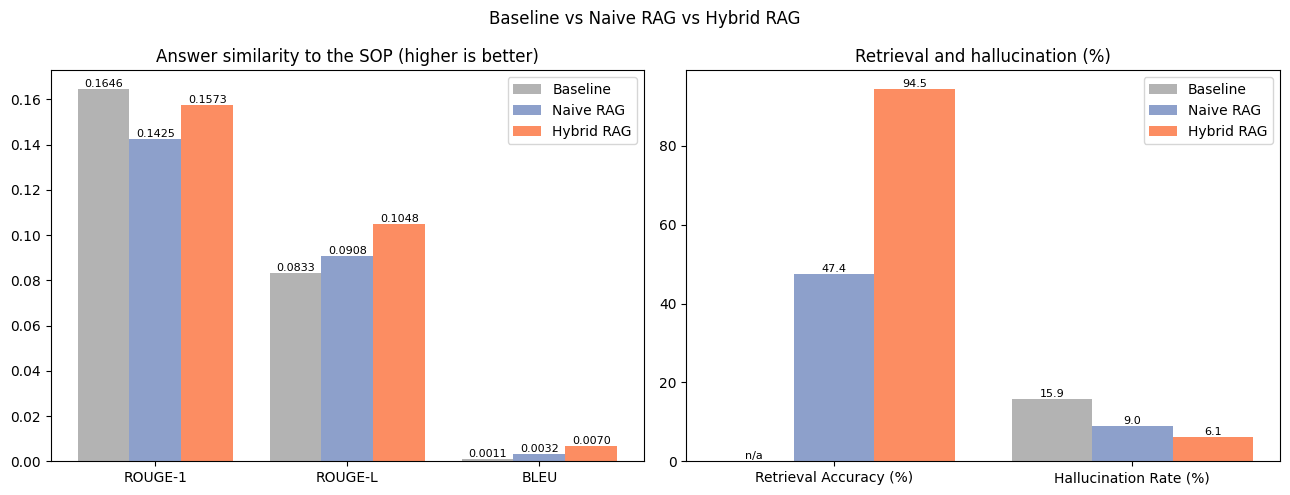

In [12]:
# ------------------------------------------------------------------
# Task 4.5 (cell 2 of 2) - Summary table, best system per metric, and plot
# ------------------------------------------------------------------
# Needs df_full from the cell above.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mapped = df_full["reference_sop"].notna()      # queries whose intent has an SOP


def summarise(key, retrieved_col=None):
    """Average scores of one system over the whole test split."""
    result = {
        "Format Adherence (%)": df_full[f"{key}_valid"].mean() * 100,
        "ROUGE-1": df_full.loc[mapped, f"{key}_rouge1"].mean(),
        "ROUGE-L": df_full.loc[mapped, f"{key}_rougeL"].mean(),
        "BLEU": df_full.loc[mapped, f"{key}_bleu"].mean(),
        "Hallucination Rate (%)": df_full[f"{key}_hallucination"].mean() * 100,
        "Avg Answer Length (words)": df_full[f"{key}_words"].mean(),
    }
    # retrieval accuracy only makes sense for systems that retrieve an SOP
    if retrieved_col is None:
        result["Retrieval Accuracy (%)"] = np.nan
    else:
        result["Retrieval Accuracy (%)"] = (
            df_full.loc[mapped, retrieved_col] == df_full.loc[mapped, "reference_sop"]
        ).mean() * 100
    return result


summary = pd.DataFrame({
    "Baseline": summarise("baseline"),
    "Naive RAG": summarise("naive", "naive_retrieved_sop"),
    "Hybrid RAG": summarise("hybrid", "hybrid_retrieved_sop"),
})

# Consistency (same query x3) was tested in Notebook 5 (Baseline, Naive RAG) and 4.4.1 (Hybrid RAG)
v1_saved = pd.read_csv("v1_metrics.csv").set_index("Metric")
v2_saved = pd.read_csv("v2_metrics.csv").set_index("Metric")
summary.loc["Consistency (%)"] = [
    v1_saved.loc["Consistency (%)", "Baseline"],
    v1_saved.loc["Consistency (%)", "Naive RAG"],
    v2_saved.loc["Consistency (%)", "Hybrid RAG"],
]

# Order the rows and name the best system for each metric
order = ["Format Adherence (%)", "ROUGE-1", "ROUGE-L", "BLEU", "Hallucination Rate (%)",
         "Retrieval Accuracy (%)", "Consistency (%)", "Avg Answer Length (words)"]
summary = summary.loc[order]


def best_system(metric, row):
    if metric == "Avg Answer Length (words)":
        return ""                                   # length is not better or worse
    values = row.dropna()
    if values.nunique() == 1:
        return "Tie"
    return values.idxmin() if metric == "Hallucination Rate (%)" else values.idxmax()


summary["Best"] = [best_system(m, summary.loc[m, ["Baseline", "Naive RAG", "Hybrid RAG"]]) for m in summary.index]

summary.index.name = "Metric"
print("COMPARATIVE RESULTS: Baseline vs Naive RAG vs Hybrid RAG")
print(summary.round(4).to_string())
summary.round(4).to_csv("Comparative_Results_Summary.csv")
print("\nSaved Comparative_Results_Summary.csv")

# Plot: left = ROUGE / BLEU, right = retrieval accuracy and hallucination (in %)
systems = ["Baseline", "Naive RAG", "Hybrid RAG"]
colors = ["#b3b3b3", "#8da0cb", "#fc8d62"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metrics, title in [
    (axes[0], ["ROUGE-1", "ROUGE-L", "BLEU"], "Answer similarity to the SOP (higher is better)"),
    (axes[1], ["Retrieval Accuracy (%)", "Hallucination Rate (%)"], "Retrieval and hallucination (%)"),
]:
    for j, (name, color) in enumerate(zip(systems, colors)):
        values = [summary.loc[m, name] for m in metrics]
        positions = [i + (j - 1) * 0.27 for i in range(len(metrics))]
        ax.bar(positions, np.nan_to_num(values), width=0.27, label=name, color=color)
        for p, v in zip(positions, values):
            label = "n/a" if np.isnan(v) else (f"{v:.4f}" if v < 1 else f"{v:.1f}")
            ax.text(p, 0 if np.isnan(v) else v, label, ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(metrics)))
    ax.set_xticklabels(metrics)
    ax.set_title(title)
    ax.legend()

plt.suptitle("Baseline vs Naive RAG vs Hybrid RAG")
plt.tight_layout()
plt.savefig("comparative_analysis.png", dpi=150)
plt.show()

##### 4.5 Comparative analysis: Baseline vs Naive RAG vs Hybrid RAG

**What we did:** All three architectures were scored on the **same 391 held-out test queries** with **SOP-grounded references**: the reference for each query is the SOP that covers its true intent. The 289 queries whose intent has an SOP are used for ROUGE and BLEU, and the other 102 are left out of those two metrics. All answers had already been generated (Notebooks 5 and 7), so this step only lines them up and scores them with the same methods as before.

| System | How the answer is made |
|---|---|
| **Baseline** | plain model, no retrieval |
| **Naive RAG** | plain model + top-1 SOP found with the customer's raw message |
| **Hybrid RAG** | plain model + top-1 SOP found with the fine-tuned router's intent |

**Files saved:** `Comparative_Results_Full.csv` (per query, 28 columns), `Comparative_Results_Summary.csv` (averages) and `comparative_analysis.png`.

---

##### 4.5 Results

| Metric | Baseline | Naive RAG | Hybrid RAG | Best |
|---|---|---|---|---|
| Format adherence | 100% | 100% | 100% | tie |
| ROUGE-1 | **0.1646** | 0.1425 | 0.1573 | Baseline |
| ROUGE-L | 0.0833 | 0.0908 | **0.1048** | Hybrid RAG |
| BLEU | 0.0011 | 0.0032 | **0.0070** | Hybrid RAG |
| Hallucination rate (lower is better) | 15.86% | 8.95% | **6.14%** | Hybrid RAG |
| Retrieval accuracy | n/a | 47.40% | **94.46%** | Hybrid RAG |
| Consistency | 100% | 100% | 100% | tie |
| Average answer length (words) | 75.7 | 52.0 | 52.6 | - |

**Reading the plots**
- *Left panel (answer similarity to the SOP):* Hybrid RAG has the highest ROUGE-L and BLEU. For ROUGE-1 the Baseline bar is the tallest. BLEU is tiny for all three systems.
- *Right panel:* retrieval accuracy goes from 47.4% (Naive RAG) to 94.5% (Hybrid RAG), and the hallucination rate falls steadily from 15.9% (Baseline) to 9.0% (Naive RAG) to 6.1% (Hybrid RAG). The Baseline has no retrieval, so its bar is shown as n/a.

---

##### 4.5 Conclusion

- **Hybrid RAG is the best system overall.** It has the best ROUGE-L, BLEU, hallucination rate and retrieval accuracy. Compared with the Baseline, the hallucination rate drops by about 61% (15.86% to 6.14%) and ROUGE-L rises by about 26%.
- **Each step adds something.** Adding retrieval (Baseline to Naive RAG) cuts hallucination from 15.86% to 8.95%. Adding the fine-tuned router (Naive RAG to Hybrid RAG) lifts retrieval accuracy from 47.4% to 94.5% and cuts hallucination further to 6.14%. Together, the two steps account for the full improvement.
- **Hybrid does not win everything.** The Baseline has a slightly higher ROUGE-1 (0.1646 vs 0.1573). Its answers are longer (75.7 vs 52.6 words), which likely helps single-word overlap with the SOP. ROUGE-L and BLEU, which reward word order and longer matches, favour Hybrid RAG.
- **Format adherence and consistency are the same for all three.** All use the same answer model with deterministic decoding, so the fine-tuning improved what is retrieved and not how the answer is written.

**Limitations**
- "Correct SOP" depends on our own intent → SOP mapping. It is the same for all systems, so the comparison is fair, but the mapping is an assumption, and 102 of the 391 queries have no SOP.
- ROUGE and BLEU are low in absolute terms, because the answers are short and the reference is a whole SOP document. They are best read as a comparison between systems.
- The hallucination check only looks for unsupported numbers, emails and links, so it does not catch every kind of wrong answer.
- The results come from one test split with deterministic decoding, with no repeated runs.

---


In [17]:
# ------------------------------------------------------------------
# Worked example: one test query, answered by all 3 systems
# ------------------------------------------------------------------
# Reads the saved results (Comparative_Results_Full.csv) - nothing is re-run.

import pandas as pd

results = pd.read_csv("Comparative_Results_Full.csv")

query = "i need information about delivery periods"
row = results[results["instruction"] == query].iloc[0]

print("QUERY       :", row["instruction"])
print("True intent :", row["intent"], "|", row["category"])
print("Router said :", row["pred_intent"])
print("Reference SOP:", row["reference_sop"])
print("=" * 70)

systems = [
    ("BASELINE (no retrieval)",  "baseline_output",  "baseline",  "n/a (no retrieval)"),
    ("SOLUTION V1 (Naive RAG)",  "naive_rag_output", "naive",     row["naive_retrieved_sop"]),
    ("SOLUTION V2 (Hybrid RAG)", "hybrid_output",    "hybrid",    row["hybrid_retrieved_sop"]),
]

for title, out_col, prefix, sop in systems:
    print(f"\n{title}")
    print("-" * 70)
    print("Retrieved SOP :", sop)
    print("Answer        :", row[out_col])

# Scores for this one query, side by side
summary = pd.DataFrame({
    "System": [s[0] for s in systems],
    "Retrieved SOP": [s[3] for s in systems],
    "ROUGE-1": [round(row[f"{s[2]}_rouge1"], 4) for s in systems],
    "ROUGE-L": [round(row[f"{s[2]}_rougeL"], 4) for s in systems],
    "BLEU": [round(row[f"{s[2]}_bleu"], 4) for s in systems],
    "Unsupported number/email/link": [bool(row[f"{s[2]}_hallucination"]) for s in systems],
    "Words": [int(row[f"{s[2]}_words"]) for s in systems],
})
print()
print(summary.to_string(index=False))

QUERY       : i need information about delivery periods
True intent : delivery_period | DELIVERY
Router said : delivery_period
Reference SOP: shipping_delays.md

BASELINE (no retrieval)
----------------------------------------------------------------------
Retrieved SOP : n/a (no retrieval)
Answer        : The delivery period for an item typically refers to the time frame during which it is expected to be delivered from the point of purchase until its arrival at the customer's location. This can vary depending on several factors including shipping speed, distance, and any additional services or options that may be included in the order.

Here’s how you might consider different aspects of delivery periods:

1. **Shipping Speed**: Different countries have varying shipping speeds. For example:
   - In the United States, items often arrive within 3-5 days.
   - In Europe, deliveries can take up to 7-1

SOLUTION V1 (Naive RAG)
----------------------------------------------------------------

#### Worked example: how the results improved

**Query:** "i need information about delivery periods" (true intent: `delivery_period`, reference SOP: `shipping_delays.md`). The router predicted `delivery_period`, which is correct.

| System | Retrieved SOP | What the answer does | ROUGE-L | Unsupported number, email or link |
| --- | --- | --- | --- | --- |
| Baseline | None | Gives a general explanation from the model's own knowledge, including country-specific delivery times ("3-5 days" in the US), and is cut off at the token limit | 0.0977 | Yes |
| Solution V1 (Naive RAG) | order_tracking.md (wrong) | Says the period "varies" and tells the customer to ask the shipping company | 0.0612 | No |
| Solution V2 (Hybrid RAG) | shipping_delays.md (correct) | States the SOP's timelines: 3-7 business days (domestic) and 10-21 business days (international) | 0.1605 | No |

**What improved**
- **Retrieval:** Naive RAG searched with the raw message and picked the wrong SOP. The fine-tuned router named the intent first (`delivery_period`), and the search found the correct SOP.
- **Answer content:** With the right SOP, Hybrid RAG gave the actual timelines from the company's policy. The Baseline answered from general knowledge, and Naive RAG could only point the customer elsewhere.
- **Scores:** ROUGE-L rose from 0.0612 (Naive RAG) to 0.1605 (Hybrid), and the Baseline's unsupported details were removed.

**Caution:** The Baseline has the highest ROUGE-1 on this query (0.2701, against 0.2140 for Hybrid) because its answer is about twice as long. This matches the overall results, where the Baseline also keeps the best ROUGE-1. One query is an illustration, not proof. The averages over all 391 queries are in section 4.5.1.

---
## END-OF-NOTEBOOK CHECKLIST (FINAL)

> **IMPORTANT: This is the last graded notebook. Verify all deliverables.**

- [x] **4.3.1** LoRA adapter integrated + Hybrid RAG validated (intent → search → retrieve → generate). Merge tested in 4-bit and 16-bit; adapter kept unmerged
- [x] **4.4.1** Format Adherence + Exact Match + Fuzzy Match on test split + adversarial subset
- [x] **4.4.2** Fine-tuning impact quantified (V1 vs V2 with %)
- [x] **4.5** All 3 architectures scored with SOP-grounded references
- [x] **`Comparative_Results_Full.csv` saved** ← _FINAL DELIVERABLE_
- [x] **`Comparative_Results_Summary.csv` saved** ← _FINAL DELIVERABLE_

### Complete Artifact Inventory

| Artifact | Created In |
|---|---|
| `sampled_data.csv` | NB1 |
| `./tokenized_train/`, `./tokenized_valid/`, `df_test.csv` | NB2 |
| `outputs.json` | NB3 + NB4 |
| `./chroma_db/` | NB4 |
| `v1_metrics.csv` | NB5 |
| `./intent_lora_best/`, `training_log.csv`, `training_curves.png` | NB6 |
| `router_predictions.csv`, `hybrid_results.csv`, `v2_metrics.csv`, `v1_vs_v2_comparison.csv`, `v1_vs_v2_comparison.png` | NB7 |
| `Comparative_Results_Full.csv`, `Comparative_Results_Summary.csv`, `comparative_analysis.png` | NB7 |

**All items checked. Next: prepare the final submission package.**